#  Medical Insurance Cost Predictor

## Overview
This project predicts individual medical insurance charges based on demographic 
and lifestyle features such as age, BMI, smoking status, and region.

The dataset contains 1338 records with 7 features. Multiple regression models 
were trained and compared to identify the best performing model for deployment

## Tech Stack
`Python` `Pandas` `Scikit-learn` `XGBoost` `Flask` `Docker` `Matplotlib` `Seaborn`

### IMPORTING DEPENDENCIES ###

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

### DATA COLLECTION AND ANALYSIS ###

In [33]:
#loading the data from csv file to dataframe
df = pd.read_csv("/kaggle/input/datasets/aditixlg/medical-cost/insurance.csv")

In [34]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [35]:
# no. of row and columns
df.shape

(1338, 7)

In [36]:
#some info about dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


#### Catogerical Features: Sex , Smoker , Region ####

In [37]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [38]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


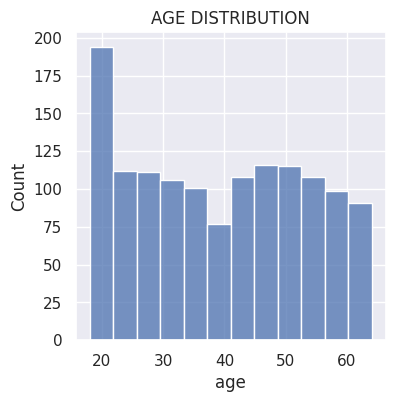

Average Age = 39.21 years


In [39]:
#AGE VALUE DISTRIBUTION
sns.set()
plt.figure(figsize = (4,4))
sns.histplot(df['age'])
plt.title('AGE DISTRIBUTION')
plt.show()
avg_age = df['age'].mean()
print("Average Age =", round(avg_age, 2), "years")

#### Average age is around 40 Years ####

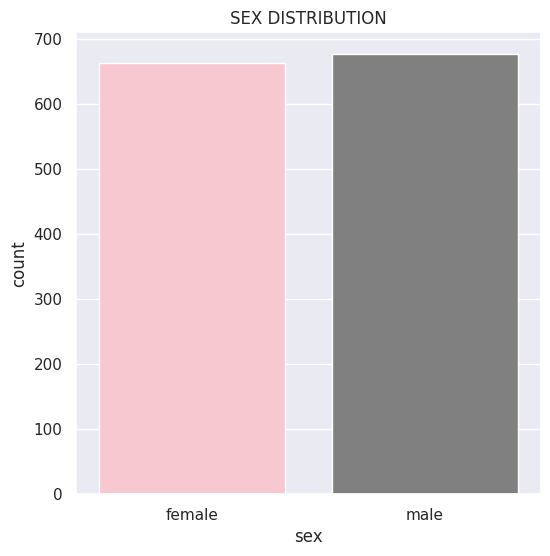

sex
male      676
female    662
Name: count, dtype: int64

In [40]:
#GENERAL COLUMN
plt.figure(figsize = (6,6))
sns.countplot(x='sex', data=df, hue='sex', palette=['pink', 'grey'], legend=False)
plt.title('SEX DISTRIBUTION')
plt.show()
df['sex'].value_counts()

#### No. of males and females are almost equal ####

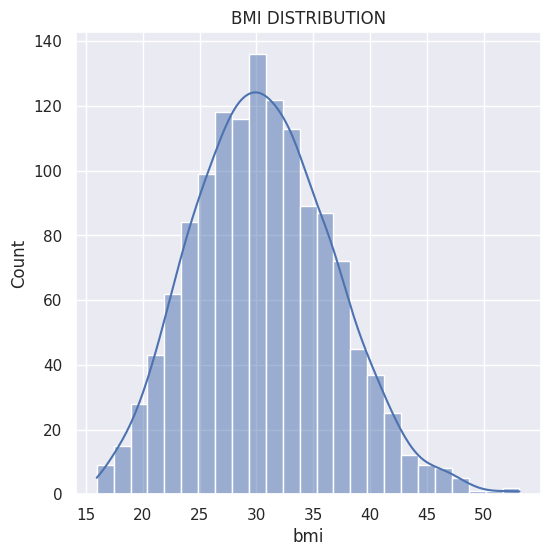

Average BMI = 30.66
Normal BMI 18 to 29


In [41]:
#BMI DISTRIBUTION
sns.set()
plt.figure(figsize = (6,6))
sns.histplot(df['bmi'] , kde= True)
plt.title('BMI DISTRIBUTION')
plt.show()
avg_bmi = df['bmi'].mean()
print("Average BMI =", round(avg_bmi, 2))
print("Normal BMI 18 to 29")

 #### BMI is approximately normally distributed with an average of 30.66, which falls in the obese category ####

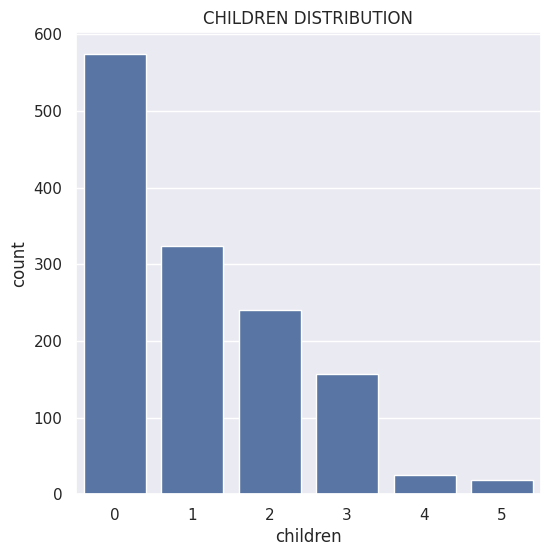

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

In [42]:
# CHILDREN COLUMN
plt.figure(figsize = (6,6))
sns.countplot(x = 'children' , data = df)
plt.title('CHILDREN DISTRIBUTION')
plt.show()
df['children'].value_counts()

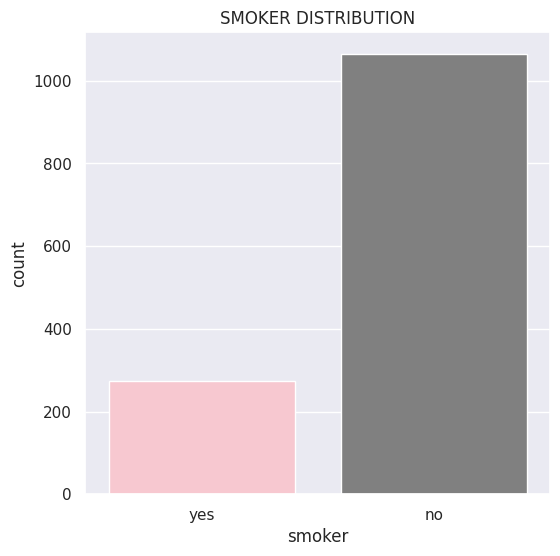

smoker : 274
Non-smoker : 1064


In [43]:
#SMOKER COLUMN 
plt.figure(figsize = (6,6))
sns.countplot(x = 'smoker' , data = df, hue = 'smoker' , palette=['pink','grey'] , legend = False )
plt.title('SMOKER DISTRIBUTION')
plt.show()
smoker_count = df['smoker'].value_counts()
print("smoker :" ,smoker_count['yes'])
print("Non-smoker :" , smoker_count['no'] )

#### Only ~20% of insured individuals are smokers (274 out of 1338), yet smoking is expected to be the strongest predictor of high insurance charges — making it a low-frequency but high-impact feature in the model. ####

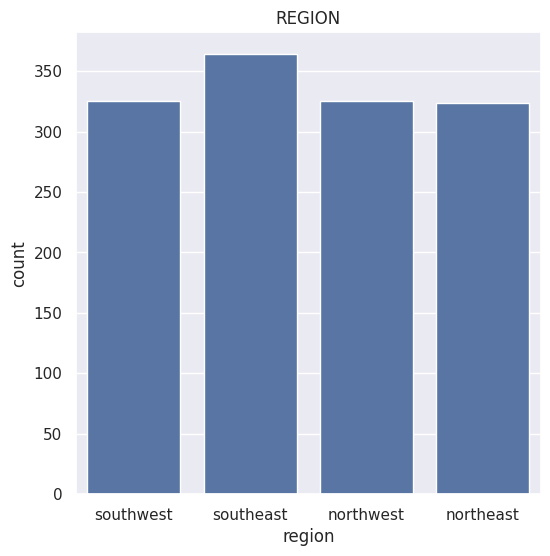

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [44]:
#REGION COLUMN
plt.figure(figsize =(6,6))
sns.countplot(x = 'region' ,data = df)
plt.title('REGION')
plt.show()
df['region'].value_counts()

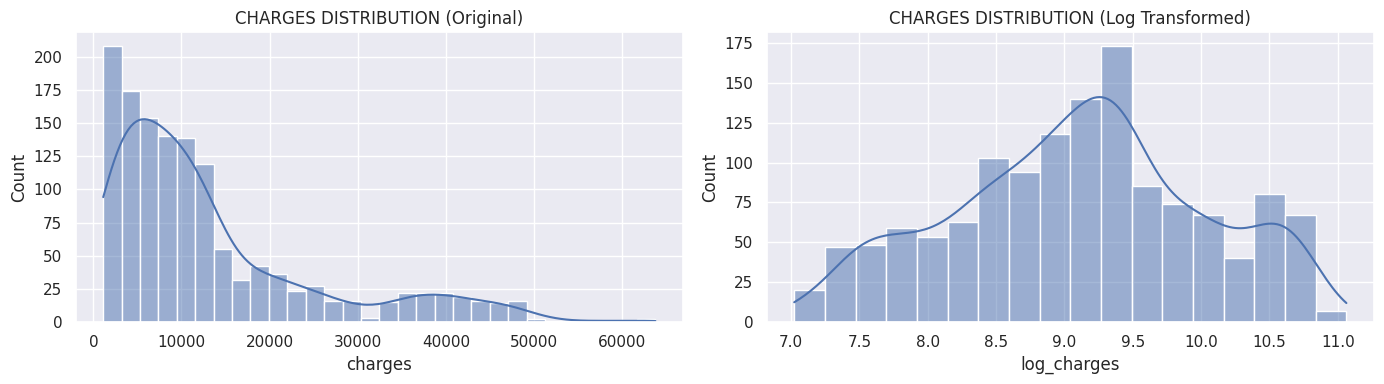

In [45]:

# DISTRIBUTION OF CHARGES
fig, axes = plt.subplots(1, 2, figsize=(14,4))

sns.histplot(df['charges'], kde = True , ax=axes[0])
axes[0].set_title('CHARGES DISTRIBUTION (Original)')

df['log_charges'] = np.log1p(df['charges'])
sns.histplot(df['log_charges'], kde = True , ax=axes[1])
axes[1].set_title('CHARGES DISTRIBUTION (Log Transformed)')

plt.tight_layout()
plt.show()



#### Original charges are heavily right-skewed with outliers beyond $60k. Log transformation compresses the tail into a near-normal distribution, making it a better target for regression. ####

## DATA PREPROCESSING ##
 ### ENCODING CATEGORICAL DATA ####

In [46]:
# encoding sex column
df['sex'] = df['sex'].map({'male': 0, 'female': 1})
# encoding smoker column  
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})
# encoding region column
df = pd.get_dummies(df, columns=['region'], drop_first=True, dtype=int)

 ## SPLITTING FEATURE AND TARGET ##

In [47]:
Y= df['log_charges']
X = df.drop(['charges', 'log_charges'], axis=1)
print(X.columns) 

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest',
       'region_southeast', 'region_southwest'],
      dtype='object')


In [48]:
X

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,0,0,1
1,18,0,33.770,1,0,0,1,0
2,28,0,33.000,3,0,0,1,0
3,33,0,22.705,0,0,1,0,0
4,32,0,28.880,0,0,1,0,0
...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,1,0,0
1334,18,1,31.920,0,0,0,0,0
1335,18,1,36.850,0,0,0,1,0
1336,21,1,25.800,0,0,0,0,1


In [49]:
Y

0        9.734236
1        7.453882
2        8.400763
3        9.998137
4        8.260455
          ...    
1333     9.268755
1334     7.699381
1335     7.396847
1336     7.605365
1337    10.279948
Name: log_charges, Length: 1338, dtype: float64

 ### SPLITTING IN TRAINING AND TESTING DATA ### 

In [50]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size = 0.2 , random_state  =42)

In [51]:
print(X.shape , X_train.shape , X_test.shape)

(1338, 8) (1070, 8) (268, 8)


 ### SCALING DATA ###

In [52]:
sr = StandardScaler()
X_train_scaled = sr.fit_transform(X_train)
X_test_scaled  = sr.transform(X_test)

In [53]:
models = {
    "LR": LinearRegression(),
    "DT": DecisionTreeRegressor(random_state=42),
    "RF": RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42),
    "GB": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "XGB": XGBRegressor(n_estimators=100, random_state=42, objective='reg:squarederror'),
    "SVR": SVR(),
    "KNN": KNeighborsRegressor(n_neighbors=5)
}

In [54]:
results = {}
for name, model in models.items():
    # Use scaled data for Linear Regression, SVR, KNN
    if name in ["LR", "SVR", "KNN"]:
        model.fit(X_train_scaled, Y_train)
        Y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, Y_train)
        Y_pred = model.predict(X_test)
    
    # Convert log-scale predictions & actuals back to original dollar scale
    Y_pred_actual = np.expm1(Y_pred)
    Y_test_actual = np.expm1(Y_test)
    
    mae = mean_absolute_error(Y_test_actual, Y_pred_actual)
    mse = mean_squared_error(Y_test_actual, Y_pred_actual)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y_test_actual, Y_pred_actual)
    
    results[name] = {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

In [55]:
result_df = pd.DataFrame(results).T
result_df.sort_values(by='R2', ascending=False)

,MAE,MSE,RMSE,R2
RF,2059.992907,1.898584e+07,4357.273959,0.877707
GB,2035.424816,1.926239e+07,4388.894261,0.875926
XGB,2381.984867,2.357230e+07,4855.131280,0.848164
SVR,2242.869059,2.495848e+07,4995.845891,0.839236
KNN,3017.662660,2.755639e+07,5249.417663,0.822502
DT,2768.376763,3.768665e+07,6138.945102,0.757250
LR,3888.443159,6.105960e+07,7814.064026,0.606698


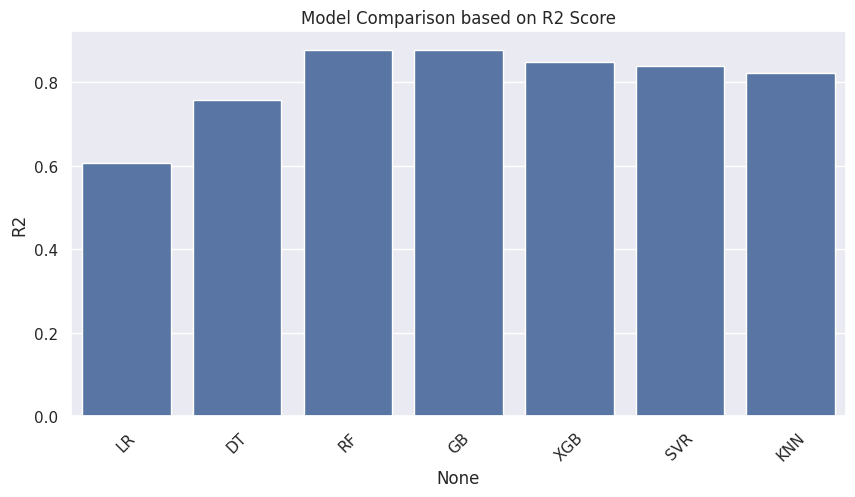

In [56]:
plt.figure(figsize=(10,5))
sns.barplot(x=result_df.index,y=result_df['R2'])
plt.title("Model Comparison based on R2 Score")
plt.xticks(rotation=45)
plt.show()

In [57]:
# ==========================================
# RANDOM FOREST HYPERPARAMETER TUNING
# ==========================================

rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 7, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', 1.0]
}


# MAE on ORIGINAL dollar scale
def original_scale_mae(y_true_log, y_pred_log):
    y_true_actual = np.expm1(y_true_log)
    y_pred_actual = np.expm1(y_pred_log)

    return mean_absolute_error(y_true_actual, y_pred_actual)


mae_scorer = make_scorer(
    original_scale_mae,
    greater_is_better=False
)


# 5-Fold Cross Validation + Randomized Search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring=mae_scorer,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, Y_train)


# ==========================================
# TUNED RANDOM FOREST
# ==========================================

best_rf = random_search.best_estimator_

Y_pred_tuned = best_rf.predict(X_test)

Y_pred_tuned_actual = np.expm1(Y_pred_tuned)
Y_test_actual = np.expm1(Y_test)

tuned_mae = mean_absolute_error(
    Y_test_actual,
    Y_pred_tuned_actual
)

tuned_rmse = np.sqrt(
    mean_squared_error(
        Y_test_actual,
        Y_pred_tuned_actual
    )
)

tuned_r2 = r2_score(
    Y_test_actual,
    Y_pred_tuned_actual
)


print("========== TUNING RESULTS ==========")
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV MAE (Original Dollar Scale):")
print(-random_search.best_score_)

print("\nTuned RF:")
print("MAE :", tuned_mae)
print("RMSE:", tuned_rmse)
print("R2  :", tuned_r2)


# ==========================================
# BASE RANDOM FOREST
# ==========================================

base_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=7,
    random_state=42
)

base_rf.fit(X_train, Y_train)

Y_pred_base = base_rf.predict(X_test)

Y_pred_base_actual = np.expm1(Y_pred_base)

base_mae = mean_absolute_error(
    Y_test_actual,
    Y_pred_base_actual
)

base_rmse = np.sqrt(
    mean_squared_error(
        Y_test_actual,
        Y_pred_base_actual
    )
)

base_r2 = r2_score(
    Y_test_actual,
    Y_pred_base_actual
)


print("\n========== BASE RANDOM FOREST ==========")
print("MAE :", base_mae)
print("RMSE:", base_rmse)
print("R2  :", base_r2)


# ==========================================
# FINAL DECISION
# ==========================================

print("\n========== FINAL DECISION ==========")

if (tuned_mae < base_mae and
    tuned_rmse < base_rmse and
    tuned_r2 > base_r2):

    final_model = best_rf
    print("Tuned Random Forest performed better across all metrics.")
    print("Selecting Tuned Random Forest as the final model.")

else:
    final_model = base_rf
    print("Tuned Random Forest did not improve consistently over the Base Random Forest.")
    print("Retaining Base Random Forest as the final model.")

========== TUNING RESULTS ==========
Best Parameters:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 5}

Best CV MAE (Original Dollar Scale):
2182.258079400751

Tuned RF:
MAE : 2092.72602267297
RMSE: 4384.130857230152
R2  : 0.87619477989528

========== BASE RANDOM FOREST ==========
MAE : 2059.9929067867292
RMSE: 4357.273959443055
R2  : 0.8777069791475456

========== FINAL DECISION ==========
Tuned Random Forest did not improve consistently over the Base Random Forest.
Retaining Base Random Forest as the final model.


In [58]:
final_model = RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42)
final_model.fit(X_train, Y_train) 

RandomForestRegressor(max_depth=7, random_state=42)

In [59]:
random_forest_model = final_model

In [60]:
import pickle
pickle.dump(random_forest_model, open('model.pkl', 'wb'))
pickle.dump(sr, open('scaler.pkl', 'wb'))

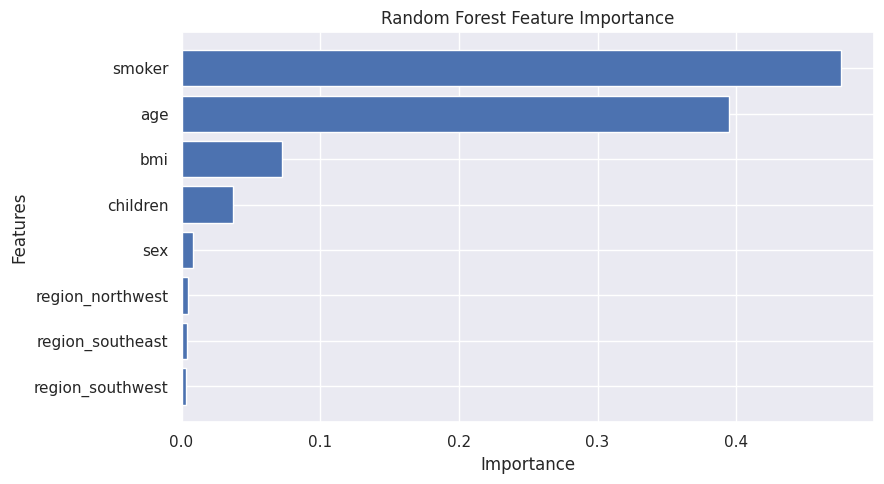

            Feature  Importance
4            smoker    0.475610
0               age    0.394719
2               bmi    0.072764
3          children    0.037081
1               sex    0.008042
5  region_northwest    0.004433
6  region_southeast    0.003833
7  region_southwest    0.003518


In [61]:
# Feature importance after One-Hot Encoding
imp = random_forest_model.feature_importances_

feature_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': imp
}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(9, 5))
plt.barh(feature_df['Feature'], feature_df['Importance'])

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Display importance values
print(feature_df)

In [62]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/aditixlg/medical-cost/insurance.csv")

avg = df.groupby("smoker")["charges"].mean()
print(avg)

ratio = avg["yes"] / avg["no"]
print(f"Smokers pay {ratio:.2f}x non-smokers on average")

smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64
Smokers pay 3.80x non-smokers on average
